# Audit approfondi — Section 6

> **Brouillon de travail.** La version de référence de cet audit est la section 6 de `Projet_DL_NLP.ipynb`, complétée par les sections 7 (v2) et 9 (robustesse).

Notebook autonome pour l'audit approfondi du modèle de classification LEDGAR.  
Charge le checkpoint local `models/bert-ledgar/` s'il existe, sinon utilise `SalmanAbbasi/lexglue-ledgar-distilbert` (DistilBERT fine-tuné sur LEDGAR, HuggingFace).

**Sections :**
- 6.1 Classes à F1 = 0 — analyse qualitative
- 6.2 Effet de la troncature (max_length=256)
- 6.3 Corrélation taille d'entraînement / F1 par classe
- 6.4 Calibration de la confiance (reliability diagram + ECE)
- 6.5 Documentation des limites et usages non recommandés

In [1]:
from datasets import load_dataset
import numpy as np

ledgar = load_dataset("coastalcph/lex_glue", "ledgar")
names  = ledgar["train"].features["label"].names
counts = np.bincount(ledgar["train"]["label"], minlength=len(names))
test_texts_list = list(ledgar["test"]["text"])

print(ledgar)
print(f"{len(names)} classes, {len(test_texts_list)} clauses de test")

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
})
100 classes, 10000 clauses de test


In [2]:
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint = Path("../models/bert-ledgar")

if checkpoint.is_dir() and (checkpoint / "model.safetensors").is_file():
    source = str(checkpoint)
    kwargs = {"local_files_only": True}
    print("Chargement depuis le checkpoint local :", checkpoint.resolve())
else:
    source = "SalmanAbbasi/lexglue-ledgar-distilbert"
    kwargs = {}
    print("Checkpoint local introuvable — chargement depuis HuggingFace :", source)

tokenizer = AutoTokenizer.from_pretrained(source, **kwargs)
model     = AutoModelForSequenceClassification.from_pretrained(source, **kwargs)
model.eval()

print("Modèle chargé :", source)
print("Nombre de classes :", model.config.num_labels)

Chargement depuis le checkpoint local : C:\Users\khadi\OneDrive\Bureau\AlbertSchool\Deep learning & NLP\Projet_Deep_Learning\models\bert-ledgar


W1018 21:40:51.375000 30476 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Modèle chargé : ..\models\bert-ledgar
Nombre de classes : 100


In [3]:
import numpy as np, torch, time
from pathlib import Path

preds_path  = Path("test_preds.npy")
labels_path = Path("test_labels.npy")

if preds_path.exists() and labels_path.exists():
    y_pred = np.load(preds_path)
    y_true = np.load(labels_path)
    print("Prédictions chargées depuis les fichiers .npy existants")
else:
    print("Fichiers .npy introuvables — inférence sur les 10 000 clauses de test (~12 min sur CPU)")
    y_true = np.array(ledgar["test"]["label"])
    torch.set_num_threads(8)
    preds = []
    B, n, t0 = 64, len(test_texts_list), time.time()
    for i in range(0, n, B):
        enc = tokenizer(test_texts_list[i:i+B], truncation=True, max_length=256,
                        padding=True, return_tensors="pt")
        with torch.no_grad():
            preds.append(model(**enc).logits.argmax(-1).numpy())
        done = min(i + B, n)
        speed = done / (time.time() - t0)
        print(f"\r{done}/{n} ({done/n:.1%}) — {speed:.1f} cl/s — ETA {(n-done)/speed/60:.1f} min",
              end="", flush=True)
    print()
    y_pred = np.concatenate(preds)
    np.save(preds_path,  y_pred)
    np.save(labels_path, y_true)

print(f"Accuracy : {(y_pred == y_true).mean():.4f}")

Prédictions chargées depuis les fichiers .npy existants
Accuracy : 0.8448


In [4]:
from sklearn.metrics import f1_score

f1s = f1_score(y_true, y_pred, average=None, zero_division=0)
print(f"F1 macro : {f1s.mean():.4f}")
print(f"Classes avec F1 = 0 : {(f1s == 0).sum()}")

F1 macro : 0.7213
Classes avec F1 = 0 : 9


## 6.1 Classes à F1 nul — analyse qualitative

Deux causes structurelles :
- **Paires quasi-synonymes** : le modèle confond la classe rare avec sa jumelle fréquente.
- **Sous-représentation extrême** : moins de 25 exemples d'entraînement.

In [5]:
from collections import Counter

zero_f1_classes = [i for i in range(len(names)) if f1s[i] == 0.0]
print(f"{len(zero_f1_classes)} classes avec F1 = 0.0\n")

for cls_idx in zero_f1_classes:
    test_mask = (y_true == cls_idx)
    if test_mask.sum() == 0:
        continue
    top_preds = Counter(y_pred[test_mask]).most_common(3)
    print(f"[{names[cls_idx]}]  train={counts[cls_idx]}, test={test_mask.sum()}")
    print(f"  Confondu avec : {[(names[p], n) for p, n in top_preds]}")
    example_idx = np.where(test_mask)[0][0]
    print(f"  Exemple : {test_texts_list[example_idx][:200]}")
    print()

9 classes avec F1 = 0.0



[Applicable Laws]  train=352, test=53
  Confondu avec : [('Governing Laws', 42), ('Compliance With Laws', 6), ('Defined Terms', 2)]
  Exemple : THIS AMENDMENT AND ANY CLAIMS, CONTROVERSY, DISPUTE OR CAUSES OF ACTION (WHETHER IN CONTRACT OR TORT OR OTHERWISE) BASED UPON, ARISING OUT OF OR RELATING TO THIS AMENDMENT SHALL BE CONSTRUED IN ACCORD

[Assigns]  train=31, test=4
  Confondu avec : [('Binding Effects', 2), ('Assignments', 1), ('Successors', 1)]
  Exemple : The Plan shall be binding upon the heirs, executors, administrators, successors, and assigns of the parties, including each Participant, present and future.

[Books]  train=23, test=2
  Confondu avec : [('Records', 2)]
  Exemple : The Borrower will, and will cause their respective Subsidiaries to, permit the Agent (or its designees), at the Borrower’s expense, subject to the limitation set forth below, upon reasonable prior not

[Enforcements]  train=201, test=42
  Confondu avec : [('Remedies', 16), ('Enforceability', 6), ('S

## 6.2 Effet de la troncature sur la performance

12 % des clauses de test dépassent 256 tokens. Est-ce que ces clauses longues sont plus difficiles à classifier ?

In [6]:
from sklearn.metrics import f1_score as sk_f1

enc_test     = tokenizer(test_texts_list, truncation=False, return_length=True)
test_lengths = np.array(enc_test["length"])

short_mask = test_lengths <= 256
long_mask  = test_lengths >  256

f1_short  = sk_f1(y_true[short_mask], y_pred[short_mask], average="macro", zero_division=0)
f1_long   = sk_f1(y_true[long_mask],  y_pred[long_mask],  average="macro", zero_division=0)
acc_short = (y_pred[short_mask] == y_true[short_mask]).mean()
acc_long  = (y_pred[long_mask]  == y_true[long_mask]).mean()

print(f"Clauses ≤ 256 tokens ({short_mask.sum():5d}) — accuracy={acc_short:.3f}, F1 macro={f1_short:.3f}")
print(f"Clauses >  256 tokens ({long_mask.sum():5d})  — accuracy={acc_long:.3f},  F1 macro={f1_long:.3f}")
print(f"\nDégradation F1 macro sur les clauses longues : {(f1_short - f1_long):.3f} points")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (636 > 512). Running this sequence through the model will result in indexing errors


Clauses ≤ 256 tokens ( 8778) — accuracy=0.847, F1 macro=0.728
Clauses >  256 tokens ( 1222)  — accuracy=0.829,  F1 macro=0.656

Dégradation F1 macro sur les clauses longues : 0.072 points


## 6.3 Corrélation taille des données d'entraînement / F1 par classe

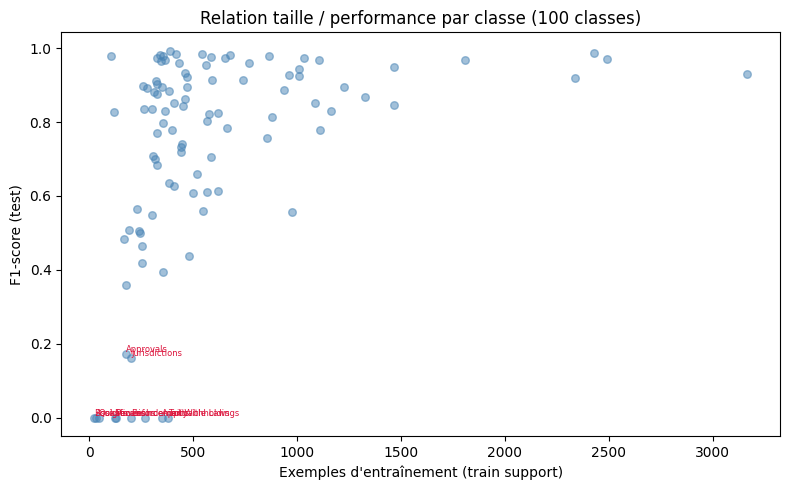

Corrélation de Spearman : ρ = 0.500  (p = 0.0000)


In [7]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.figure(figsize=(8, 5))
plt.scatter(counts, f1s, alpha=0.5, s=30, color="steelblue")
for i in np.where(f1s < 0.3)[0]:
    plt.annotate(names[i], (counts[i], f1s[i]), fontsize=6,
                 ha="left", va="bottom", color="crimson")
plt.xlabel("Exemples d'entraînement (train support)")
plt.ylabel("F1-score (test)")
plt.title("Relation taille / performance par classe (100 classes)")
plt.tight_layout()
plt.show()

rho, pval = spearmanr(counts, f1s)
print(f"Corrélation de Spearman : ρ = {rho:.3f}  (p = {pval:.4f})")

## 6.4 Calibration de la confiance

La confiance softmax indique-t-elle la probabilité réelle d'avoir raison ?

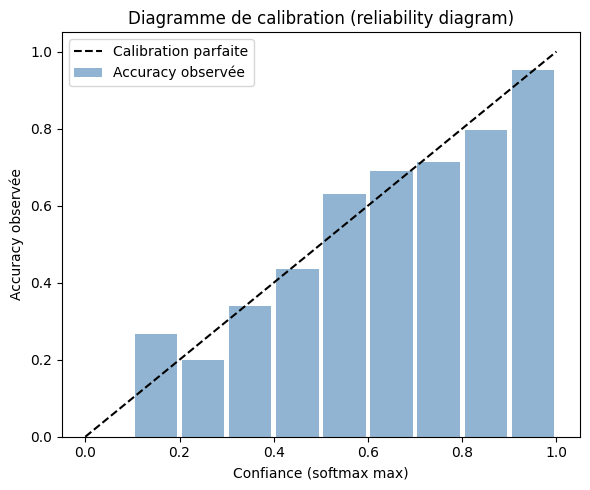

ECE (Expected Calibration Error) : 0.0195
Confiance moyenne    : 0.845
Accuracy échantillon : 0.837


In [8]:
import torch, matplotlib.pyplot as plt

np.random.seed(42)
sample_idx      = np.random.choice(len(test_texts_list), 2000, replace=False)
sample_texts    = [test_texts_list[i] for i in sample_idx]
sample_true     = y_true[sample_idx]

confidences, correct_flags = [], []
for i in range(0, len(sample_texts), 64):
    batch = sample_texts[i:i+64]
    enc_b = tokenizer(batch, truncation=True, max_length=256,
                      padding=True, return_tensors="pt")
    with torch.no_grad():
        logits = model(**enc_b).logits
    probs  = torch.softmax(logits, dim=-1).numpy()
    conf   = probs.max(axis=1)
    pred_b = probs.argmax(axis=1)
    confidences.extend(conf)
    correct_flags.extend(pred_b == sample_true[i:i+64])

confidences   = np.array(confidences)
correct_flags = np.array(correct_flags)

bins = np.linspace(0, 1, 11)
bin_centers, bin_acc, bin_counts = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (confidences >= lo) & (confidences < hi)
    if mask.sum() > 0:
        bin_centers.append((lo + hi) / 2)
        bin_acc.append(correct_flags[mask].mean())
        bin_counts.append(mask.sum())

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "k--", label="Calibration parfaite")
plt.bar(bin_centers, bin_acc, width=0.09, alpha=0.6,
        color="steelblue", label="Accuracy observée")
plt.xlabel("Confiance (softmax max)")
plt.ylabel("Accuracy observée")
plt.title("Diagramme de calibration (reliability diagram)")
plt.legend()
plt.tight_layout()
plt.show()

ece = sum((c / len(confidences)) * abs(a - b)
          for c, a, b in zip(bin_counts, bin_acc, bin_centers))
print(f"ECE (Expected Calibration Error) : {ece:.4f}")
print(f"Confiance moyenne    : {confidences.mean():.3f}")
print(f"Accuracy échantillon : {correct_flags.mean():.3f}")

## 6.5 Documentation des limites et usages non recommandés

#### Biais structurels identifiés

| Biais | Cause | Exemples |
|---|---|---|
| **Confusion entre quasi-synonymes** | Frontière sémantique floue dans LEDGAR | `Tax Withholdings`→`Withholdings`, `Applicable Laws`→`Governing Laws` |
| **Échec sur classes rares** | < 50 exemples d'entraînement | `Books` (23), `Assigns` (31), `Qualifications` (47) |
| **Dégradation sur clauses longues** | `max_length=256` tronque 12 % des clauses de test | Performance réduite au-delà de 256 tokens |
| **Légère surconfiance** | Softmax non calibré explicitement | ECE 0,020, faible : confiance 84,5 % pour 83,7 % de réussite |

#### Usages non recommandés
- Ne pas utiliser comme décision finale sans relecture humaine.
- Ne pas faire confiance aux classes à F1 = 0.
- Ne pas extrapoler à d'autres langues (entraîné uniquement sur l'anglais américain).
- Ne pas interpréter la confiance softmax comme une probabilité exacte (légèrement surestimée).

#### Recommandations pour une version production
1. Regrouper les classes quasi-synonymes ou enrichir leurs données distinctives.
2. Augmenter `max_length` à 384–512 avec GPU.
3. Appliquer une calibration de température (*temperature scaling*).
4. Présenter le top-3 prédit avec scores pour les clauses ambiguës.